In [1]:
%pip install -U ipywidgets tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Basic libraries imported successfully!")

Basic libraries imported successfully!


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


In [4]:
from transformers import DistilBertTokenizer
from transformers import DistilBertForSequenceClassification

print("Transformers imported successfully!")

Transformers imported successfully!


In [5]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib location:", matplotlib.__file__)

Matplotlib version: 3.11.2
Matplotlib location: C:\Users\girir\anaconda3\Lib\site-packages\matplotlib\__init__.py


In [6]:
%pip install --upgrade --force-reinstall matplotlib

^C
Note: you may need to restart the kernel to use updated packages.


In [7]:
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

model_name = "distilbert-base-uncased"

tokenizer = DistilBertTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")

DistilBERT tokenizer loaded successfully!


In [8]:
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

model_name = "distilbert-base-uncased"

tokenizer = DistilBertTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")

DistilBERT tokenizer loaded successfully!


In [9]:
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

print("All required libraries imported successfully!")
print("PyTorch version:", torch.__version__)

All required libraries imported successfully!
PyTorch version: 2.14.1+cpu


In [10]:
model = DistilBertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("DistilBERT model loaded successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [11]:
import torch
import ipywidgets
import tqdm

from torch.utils.data import DataLoader, Dataset
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from torch.optim import AdamW

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("All imports completed successfully!")
print("PyTorch version:", torch.__version__)

All imports completed successfully!
PyTorch version: 2.14.1+cpu


In [12]:
import pandas as pd
import numpy as np

import re
import string

import matplotlib.pyplot as plt
import seaborn as sns

import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud

In [13]:
#Download NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\girir\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [14]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:")
print(os.listdir())

Current folder: C:\Users\girir
Files in this folder:
['.anaconda', '.cache', '.conda', '.continuum', '.copilot', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.matplotlib', '.python_history', '.streamlit', '.vscode', '.vscode-shared', '1.22.0', 'adult_with_headers.csv', 'Alphabets_data.csv', 'anaconda3', 'anime.csv', 'app.ipynb', 'app.py', 'AppData', 'Application Data', 'Association Rule.ipynb', 'Association Rules (1).zip', 'Association Rules.csv', 'Association Rules.docx', 'Association_Rules_Output.csv', 'Bankruptcy Prevention Using Machine Learning.ipynb', 'bankruptcy_model.pkl', 'Bankruptcy_prevention_Dataset.csv', 'bankruptcy_prevention_model.pkl', 'bankruptcy_scaler.pkl', 'Basic statistics.ipynb', 'Basic_statistic2.ipynb', 'blogs.csv', 'Cleaned_Cardiotocographic.csv', 'cleaned_sentiment_dataset (2).xlsx', 'cleaned_sentiment_dataset.csv', 'cleaned_sentiment_dataset.xlsx', 'Clustring.ipynb', 'Contacts', 'converted_file.csv', 'Cookies', 'CrossDevice', 'Decision 

In [15]:
import pandas as pd

df = pd.read_excel("cleaned_sentiment_dataset.xlsx")
df.head()

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,Horrible product,1,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...,Negative,76,10,76,6,8.666667,1,0,0,0,0,0.463,0.537,0.000,-0.7841
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low,Neutral,61,11,61,5,6.000000,1,0,0,0,0,0.319,0.681,0.000,-0.4956
2,Overall,4,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...,Positive,411,67,411,33,6.638889,3,0,1,0,1,0.076,0.843,0.081,0.1027
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...,Negative,394,72,394,34,5.054054,13,0,0,0,2,0.209,0.770,0.021,-0.9162
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...,Negative,209,34,209,25,5.296296,4,0,0,0,9,0.235,0.765,0.000,-0.8033


In [16]:
#Check dataset columns
print("Column Names:")
print(df.columns.tolist())

Column Names:
['title', 'rating', 'body', 'review_text', 'cleaned_text', 'sentiment', 'review_length', 'word_count', 'character_count', 'unique_word_count', 'average_word_length', 'sentence_count', 'exclamation_count', 'question_count', 'hashtag_count', 'uppercase_word_count', 'vader_negative_score', 'vader_neutral_score', 'vader_positive_score', 'vader_compound_score']


In [17]:
#Check first 5 rows
df.head()

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,Horrible product,1,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...,Negative,76,10,76,6,8.666667,1,0,0,0,0,0.463,0.537,0.000,-0.7841
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low,Neutral,61,11,61,5,6.000000,1,0,0,0,0,0.319,0.681,0.000,-0.4956
2,Overall,4,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...,Positive,411,67,411,33,6.638889,3,0,1,0,1,0.076,0.843,0.081,0.1027
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...,Negative,394,72,394,34,5.054054,13,0,0,0,2,0.209,0.770,0.021,-0.9162
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...,Negative,209,34,209,25,5.296296,4,0,0,0,9,0.235,0.765,0.000,-0.8033


In [18]:
#Check last 5 rows
df.tail()

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
1435,Excellent mobile,5,Excellent mobile,Excellent mobile Excellent mobile,excellent mobile excellent mobile,Positive,33,4,33,2,7.500000,1,0,0,0,0,0.000,0.213,0.787,0.8126
1436,Never expected from samsung,1,"All over mobile performance is very poor, neve...",Never expected from samsung All over mobile pe...,never expected samsung mobile performance poor...,Negative,216,35,216,19,6.136364,2,0,0,0,1,0.259,0.741,0.000,-0.9038
1437,Good value for money,5,Battery life is good but camera clarity could ...,Good value for money Battery life is good but ...,good value money battery life good camera clar...,Positive,119,21,119,12,5.500000,1,0,0,0,0,0.000,0.484,0.516,0.9327
1438,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied.....",Unreal and whitish display It's a very bad pro...,unreal whitish display bad product highly diss...,Negative,234,39,234,20,6.173913,4,0,0,0,1,0.141,0.809,0.050,-0.5863
1439,Beast of the best.,5,The phone is a real beast the battery lasts ea...,Beast of the best. The phone is a real beast t...,beast best phone real beast battery last easil...,Positive,226,43,226,20,5.333333,5,0,0,0,0,0.000,0.670,0.330,0.9497


In [19]:
#Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   title                 1440 non-null   str    
 1   rating                1440 non-null   int64  
 2   body                  1440 non-null   str    
 3   review_text           1440 non-null   str    
 4   cleaned_text          1440 non-null   str    
 5   sentiment             1440 non-null   str    
 6   review_length         1440 non-null   int64  
 7   word_count            1440 non-null   int64  
 8   character_count       1440 non-null   int64  
 9   unique_word_count     1440 non-null   int64  
 10  average_word_length   1440 non-null   float64
 11  sentence_count        1440 non-null   int64  
 12  exclamation_count     1440 non-null   int64  
 13  question_count        1440 non-null   int64  
 14  hashtag_count         1440 non-null   int64  
 15  uppercase_word_count  1440 non-n

In [20]:
#Check statistical summary
df.describe(include='all')

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
count,1440,1440.000000,1440,1440,1440,1440,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
unique,1351,NaN,1440,1440,1440,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Value for money,NaN,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...,Positive,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,16,NaN,1,1,1,729,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,3.173611,NaN,NaN,NaN,NaN,333.381944,58.257639,333.381944,27.367361,5.866013,5.270139,0.233333,0.022917,0.009722,1.089583,0.084256,0.753674,0.162062,0.264264
std,NaN,1.584453,NaN,NaN,NaN,NaN,229.116704,39.896874,229.116704,16.730265,1.509516,4.334030,1.219371,0.279287,0.223473,4.713283,0.092287,0.116547,0.128670,0.695083
min,NaN,1.000000,NaN,NaN,NaN,NaN,9.000000,2.000000,9.000000,2.000000,3.270270,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.987100
25%,NaN,1.000000,NaN,NaN,NaN,NaN,198.000000,34.000000,198.000000,17.000000,5.460737,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.686000,0.063750,-0.447675
50%,NaN,4.000000,NaN,NaN,NaN,NaN,277.000000,49.000000,277.000000,24.000000,5.785014,4.000000,0.000000,0.000000,0.000000,0.000000,0.060000,0.765000,0.141000,0.610350
75%,NaN,5.000000,NaN,NaN,NaN,NaN,395.000000,70.000000,395.000000,33.000000,6.156661,7.000000,0.000000,0.000000,0.000000,1.000000,0.131000,0.830000,0.236250,0.891000


In [21]:
#Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
title                   0
rating                  0
body                    0
review_text             0
cleaned_text            0
sentiment               0
review_length           0
word_count              0
character_count         0
unique_word_count       0
average_word_length     0
sentence_count          0
exclamation_count       0
question_count          0
hashtag_count           0
uppercase_word_count    0
vader_negative_score    0
vader_neutral_score     0
vader_positive_score    0
vader_compound_score    0
dtype: int64


In [22]:
#Check duplicate rows
print("Number of duplicate rows:")
print(df.duplicated().sum())

Number of duplicate rows:
0


In [23]:
#Combine title and body
#We will create one complete text column for NLP
df['review_text'] = (
    df['title'].astype(str) + " " +
    df['body'].astype(str)
)

df[['title', 'body', 'review_text']].head()

,title,body,review_text
0,Horrible product,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...
1,Camera quality is not like 48 megapixel,Camera quality is low,Camera quality is not like 48 megapixel Camera...
2,Overall,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt..."
3,A big no from me,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...
4,Put your money somewhere else,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...


In [24]:
#Check rating distribution
print(df['rating'].value_counts().sort_index())

rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


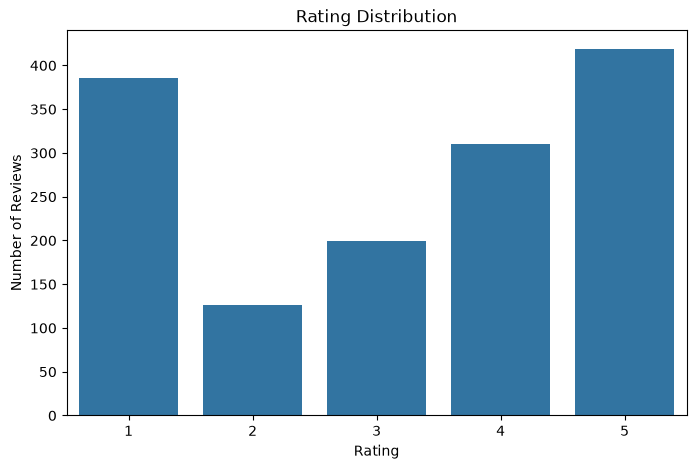

In [25]:
#Visualize rating distribution
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='rating'
)

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [26]:
#Create sentiment column
def rating_to_sentiment(rating):

    if rating <= 2:
        return 'Negative'

    elif rating == 3:
        return 'Neutral'

    else:
        return 'Positive'


df['sentiment'] = df['rating'].apply(
    rating_to_sentiment
)

In [27]:
df[['rating', 'sentiment']].head(10)

,rating,sentiment
0,1,Negative
1,3,Neutral
2,4,Positive
3,1,Negative
4,1,Negative
5,1,Negative
6,1,Negative
7,1,Negative
8,1,Negative
9,1,Negative


In [28]:
# VADER Sentiment Analysis

sia = SentimentIntensityAnalyzer()

# Calculate VADER sentiment scores
df['vader_scores'] = df['review_text'].apply(
    lambda text: sia.polarity_scores(str(text))
)

# Extract individual VADER scores
df['vader_negative'] = df['vader_scores'].apply(
    lambda x: x['neg']
)

df['vader_neutral'] = df['vader_scores'].apply(
    lambda x: x['neu']
)

df['vader_positive'] = df['vader_scores'].apply(
    lambda x: x['pos']
)

df['vader_compound'] = df['vader_scores'].apply(
    lambda x: x['compound']
)

In [29]:
# Convert VADER compound score into sentiment labels

def vader_sentiment(score):

    if score >= 0.05:
        return 'Positive'

    elif score <= -0.05:
        return 'Negative'

    else:
        return 'Neutral'


df['vader_sentiment'] = df['vader_compound'].apply(
    vader_sentiment
)

In [30]:
# Display VADER results

df[
    [
        'review_text',
        'rating',
        'sentiment',
        'vader_compound',
        'vader_sentiment'
    ]
].head(10)

,review_text,rating,sentiment,vader_compound,vader_sentiment
0,Horrible product Very disappointed with the ov...,1,Negative,-0.7841,Negative
1,Camera quality is not like 48 megapixel Camera...,3,Neutral,-0.4956,Negative
2,"Overall Got the mobile on the launch date,Batt...",4,Positive,0.1027,Positive
3,A big no from me 1. It doesn't work with 5.0GH...,1,Negative,-0.9162,Negative
4,Put your money somewhere else Not worth buying...,1,Negative,-0.8033,Negative
5,Too much lagging and slow I will never purchas...,1,Negative,-0.7506,Negative
6,Worst samsung mobile ever This is worst samsun...,1,Negative,-0.7845,Negative
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,1,Negative,0.0000,Neutral
8,Slow performance The phone hangs a lot and is ...,1,Negative,0.0000,Neutral
9,Don’t buy from Amazon. Very poor quality camer...,1,Negative,-0.6361,Negative


In [31]:
#Sentiment distribution and vader sentiment distribution
print(df['sentiment'].value_counts())
print(df['vader_sentiment'].value_counts())

sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64
vader_sentiment
Positive    909
Negative    487
Neutral      44
Name: count, dtype: int64


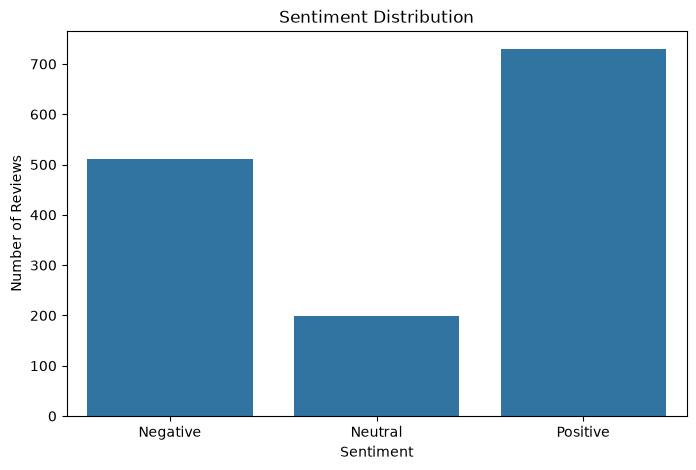

In [32]:
#Sentiment visualization
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='sentiment'
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

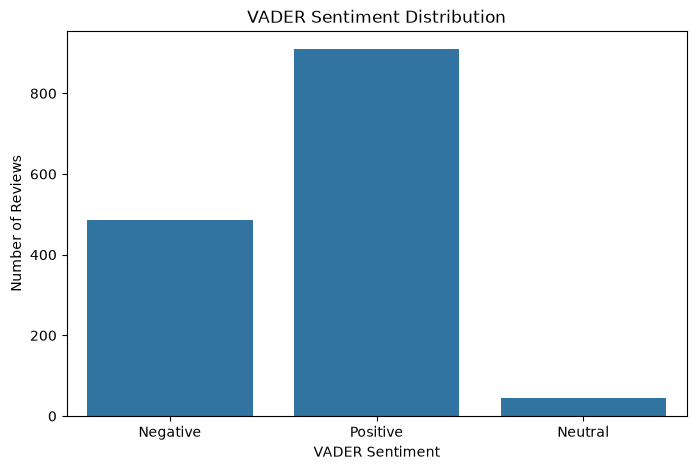

In [33]:
#VADER sentiment distribution
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='vader_sentiment'
)

plt.title("VADER Sentiment Distribution")
plt.xlabel("VADER Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [34]:
# Compare Rating-based Sentiment with VADER Sentiment

comparison = pd.crosstab(
    df['sentiment'],
    df['vader_sentiment']
)

print(comparison)

vader_sentiment  Negative  Neutral  Positive
sentiment                                   
Negative              361       21       130
Neutral                81        6       112
Positive               45       17       667


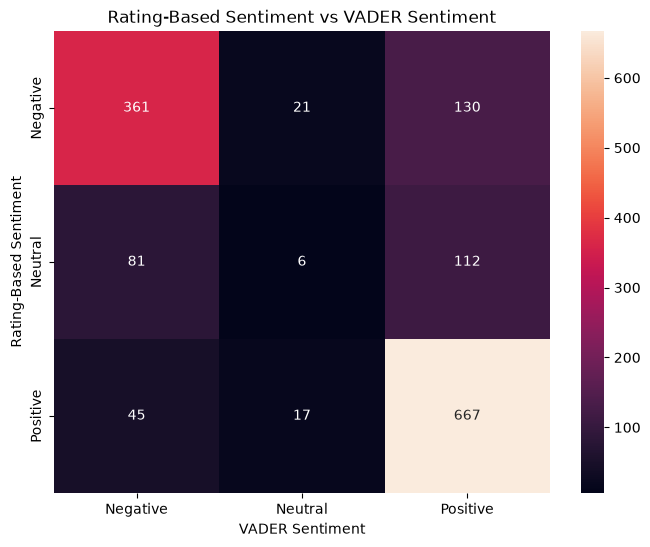

In [35]:
#vistualization
plt.figure(figsize=(8,6))

sns.heatmap(
    comparison,
    annot=True,
    fmt='d'
)

plt.title(
    "Rating-Based Sentiment vs VADER Sentiment"
)

plt.xlabel("VADER Sentiment")
plt.ylabel("Rating-Based Sentiment")

plt.show()

In [36]:
#Initialize stopwords and lemmatizer
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

In [37]:
#NLP preprocessing function
def preprocess_text(text):

    # Convert to string
    text = str(text)

    # 1. Lowercasing
    text = text.lower()


    # 2. Remove URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text
    )


    # 3. Remove @mention
    text = re.sub(
        r'@\w+',
        ' ',
        text
    )


    # 4. Handle hashtags
    # Example:
    # #amazon -> amazon
    text = re.sub(
        r'#(\w+)',
        r'\1',
        text
    )


    # 5. Remove HTML tags
    text = re.sub(
        r'<.*?>',
        ' ',
        text
    )


    # 6. Remove numbers
    text = re.sub(
        r'\d+',
        ' ',
        text
    )


    # 7. Remove punctuation
    text = text.translate(
        str.maketrans(
            '',
            '',
            string.punctuation
        )
    )


    # 8. Normalize whitespace
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()


    # 9. Tokenization
    tokens = word_tokenize(text)


    # 10. Stopword removal
    tokens = [
        word
        for word in tokens
        if word not in stop_words
    ]


    # 11. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]


    # 12. Remove very short words
    tokens = [
        word
        for word in tokens
        if len(word) > 1
    ]


    return tokens

In [38]:
#Apply preprocessing
df['tokens'] = df['review_text'].apply(
    preprocess_text
)

In [39]:
df[['review_text', 'tokens']].head()

,review_text,tokens
0,Horrible product Very disappointed with the ov...,"[horrible, product, disappointed, overall, per..."
1,Camera quality is not like 48 megapixel Camera...,"[camera, quality, like, megapixel, camera, qua..."
2,"Overall Got the mobile on the launch date,Batt...","[overall, got, mobile, launch, datebattery, mu..."
3,A big no from me 1. It doesn't work with 5.0GH...,"[big, doesnt, work, ghz, wifi, frequency, ghz,..."
4,Put your money somewhere else Not worth buying...,"[put, money, somewhere, else, worth, buyingfau..."


In [40]:
df[
    [
        'review_text',
        'cleaned_text'
    ]
].head(10)

,review_text,cleaned_text
0,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...
1,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low
2,"Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...
3,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...
4,Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...
5,Too much lagging and slow I will never purchas...,much lagging slow never purchase samsung phone...
6,Worst samsung mobile ever This is worst samsun...,worst samsung mobile ever worst samsung mobile...
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,कैसा दिखाते है उसका भी नही मोबाइल का कैमरा बिल...
8,Slow performance The phone hangs a lot and is ...,slow performance phone hang lot slow received ...
9,Don’t buy from Amazon. Very poor quality camer...,buy amazon poor quality camera found box seal ...


In [41]:
#Create cleaned text
df['cleaned_text'] = df['tokens'].apply(
    lambda x: ' '.join(x)
)

In [42]:
df[
    [
        'review_text',
        'cleaned_text'
    ]
].head(10)

,review_text,cleaned_text
0,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...
1,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low
2,"Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...
3,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...
4,Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...
5,Too much lagging and slow I will never purchas...,much lagging slow never purchase samsung phone...
6,Worst samsung mobile ever This is worst samsun...,worst samsung mobile ever worst samsung mobile...
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,कैसा दिखाते है उसका भी नही मोबाइल का कैमरा बिल...
8,Slow performance The phone hangs a lot and is ...,slow performance phone hang lot slow received ...
9,Don’t buy from Amazon. Very poor quality camer...,buy amazon poor quality camera found box seal ...


In [43]:
#Create Review Length feature
df['review_length'] = df['review_text'].apply(
    len
)

In [44]:
#Create Word Count feature
df['word_count'] = df['review_text'].apply(
    lambda x: len(str(x).split())
)

In [45]:
#Create Character Count feature
df['character_count'] = df['review_text'].apply(
    len
)

In [46]:
#Create Unique Word Count feature
df['unique_word_count'] = df['tokens'].apply(
    lambda x: len(set(x))
)

In [47]:
#Create Average Word Length feature
df['average_word_length'] = df['tokens'].apply(
    lambda x: np.mean(
        [len(word) for word in x]
    ) if len(x) > 0 else 0
)

In [48]:
#Create Sentence Count feature
def count_sentences(text):

    sentences = re.split(
        r'[.!?]+',
        str(text)
    )

    sentences = [
        sentence
        for sentence in sentences
        if sentence.strip()
    ]

    return len(sentences)


df['sentence_count'] = df['review_text'].apply(
    count_sentences
)

In [49]:
#Create Exclamation Count
df['exclamation_count'] = df['review_text'].apply(
    lambda x: str(x).count('!')
)

In [50]:
#Create Question Count
df['question_count'] = df['review_text'].apply(
    lambda x: str(x).count('?')
)

In [51]:
#Create Hashtag Count
df['hashtag_count'] = df['review_text'].apply(
    lambda x: len(
        re.findall(
            r'#\w+',
            str(x)
        )
    )
)

In [52]:
#Create Uppercase Word Count
def uppercase_word_count(text):

    words = str(text).split()

    return sum(
        1
        for word in words
        if word.isupper() and len(word) > 1
    )


df['uppercase_word_count'] = df['review_text'].apply(
    uppercase_word_count
)

In [53]:
# Add VADER sentiment scores as features

df['vader_negative_score'] = df['vader_negative']
df['vader_neutral_score'] = df['vader_neutral']
df['vader_positive_score'] = df['vader_positive']
df['vader_compound_score'] = df['vader_compound']

In [54]:
#Check all engineered features
feature_columns = [
    'review_length',
    'word_count',
    'character_count',
    'unique_word_count',
    'average_word_length',
    'sentence_count',
    'exclamation_count',
    'question_count',
    'hashtag_count',
    'uppercase_word_count',
    'vader_negative_score',
    'vader_neutral_score',
    'vader_positive_score',
    'vader_compound_score'
]

df[feature_columns].head(10)

,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,76,10,76,6,8.666667,1,0,0,0,0,0.463,0.537,0.000,-0.7841
1,61,11,61,5,6.000000,1,0,0,0,0,0.319,0.681,0.000,-0.4956
2,411,67,411,33,6.638889,3,0,1,0,1,0.076,0.843,0.081,0.1027
3,394,72,394,34,5.054054,13,0,0,0,2,0.209,0.770,0.021,-0.9162
4,209,34,209,25,5.296296,4,0,0,0,9,0.235,0.765,0.000,-0.8033
5,128,23,128,11,5.400000,3,0,0,0,0,0.318,0.682,0.000,-0.7506
6,205,37,205,17,5.260870,4,0,0,0,0,0.193,0.753,0.054,-0.7845
7,167,37,167,23,3.787879,1,0,0,0,1,0.000,1.000,0.000,0.0000
8,105,19,105,8,6.300000,2,0,0,0,0,0.000,1.000,0.000,0.0000
9,210,32,210,20,6.000000,7,0,0,0,0,0.236,0.579,0.185,-0.6361


In [55]:
#Check statistics of engineered features
df[feature_columns].describe()

,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
count,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,333.381944,58.257639,333.381944,27.367361,5.866013,5.270139,0.233333,0.022917,0.009722,1.089583,0.084256,0.753674,0.162062,0.264264
std,229.116704,39.896874,229.116704,16.730265,1.509516,4.334030,1.219371,0.279287,0.223473,4.713283,0.092287,0.116547,0.128670,0.695083
min,9.000000,2.000000,9.000000,2.000000,3.270270,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.987100
25%,198.000000,34.000000,198.000000,17.000000,5.460737,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.686000,0.063750,-0.447675
50%,277.000000,49.000000,277.000000,24.000000,5.785014,4.000000,0.000000,0.000000,0.000000,0.000000,0.060000,0.765000,0.141000,0.610350
75%,395.000000,70.000000,395.000000,33.000000,6.156661,7.000000,0.000000,0.000000,0.000000,1.000000,0.131000,0.830000,0.236250,0.891000
max,2536.000000,391.000000,2536.000000,163.000000,57.333333,43.000000,23.000000,7.000000,8.000000,89.000000,0.758000,1.000000,1.000000,0.995300


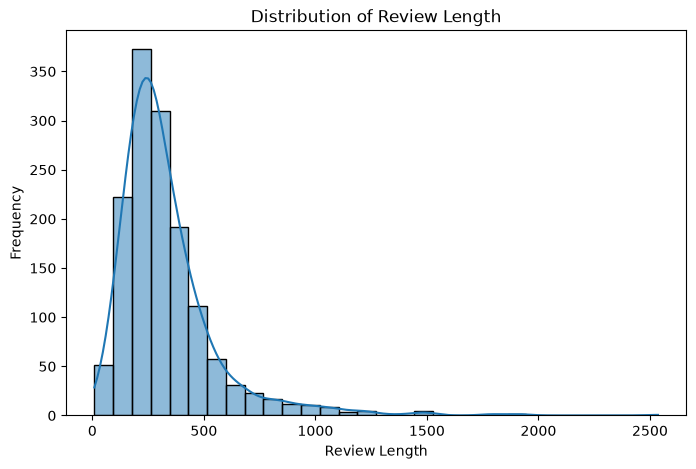

In [56]:
#Review length distribution
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='review_length',
    bins=30,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length")
plt.ylabel("Frequency")

plt.show()

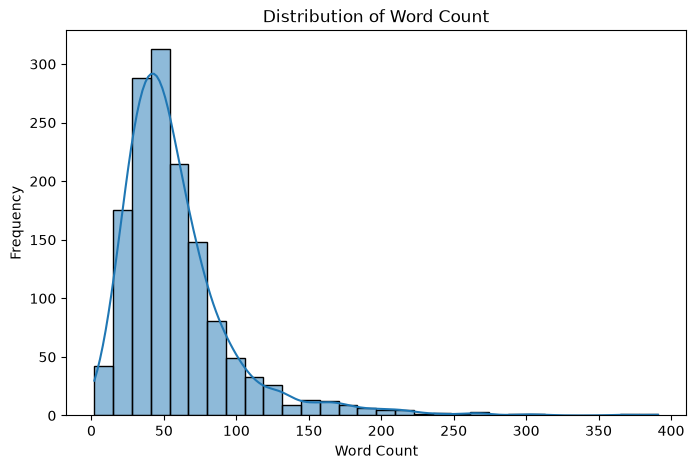

In [57]:
#Word count distribution
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='word_count',
    bins=30,
    kde=True
)

plt.title("Distribution of Word Count")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

plt.show()

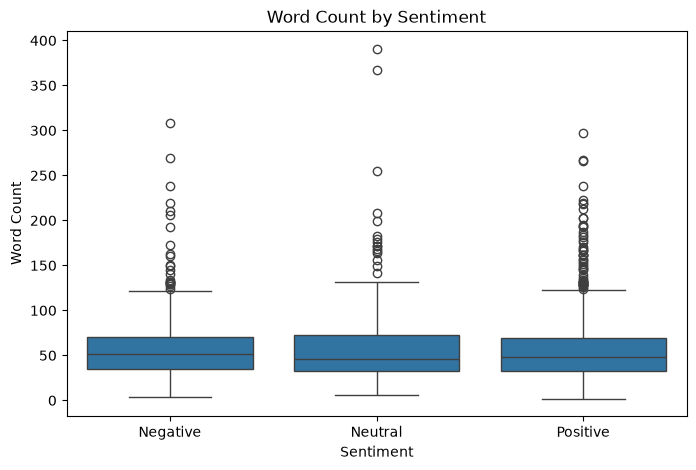

In [58]:
#Word count by sentiment
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='sentiment',
    y='word_count'
)

plt.title("Word Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")

plt.show()

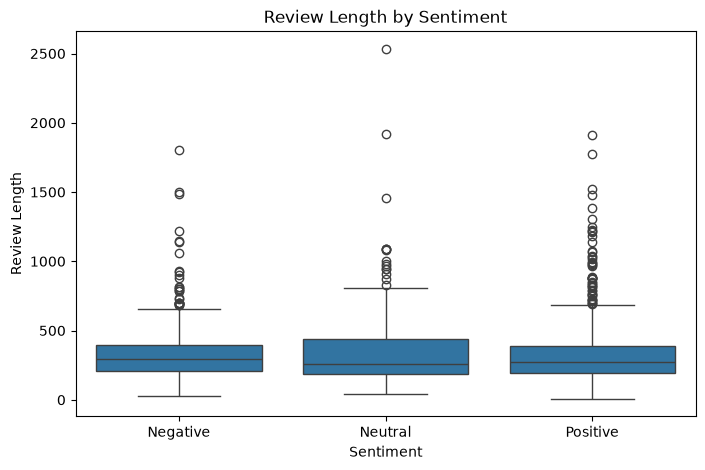

In [59]:
#Review length by sentiment
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='sentiment',
    y='review_length'
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length")

plt.show()

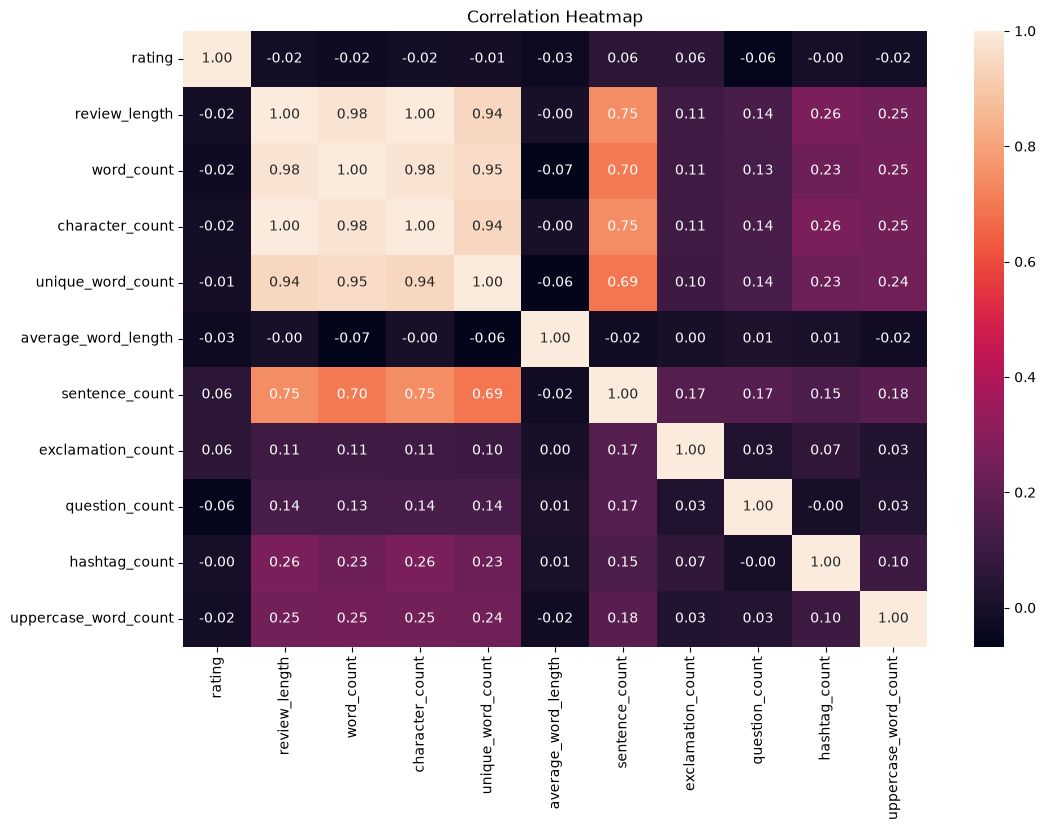

In [60]:
#Correlation heatmap
numeric_features = [
    'rating',
    'review_length',
    'word_count',
    'character_count',
    'unique_word_count',
    'average_word_length',
    'sentence_count',
    'exclamation_count',
    'question_count',
    'hashtag_count',
    'uppercase_word_count'
]

plt.figure(figsize=(12,8))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

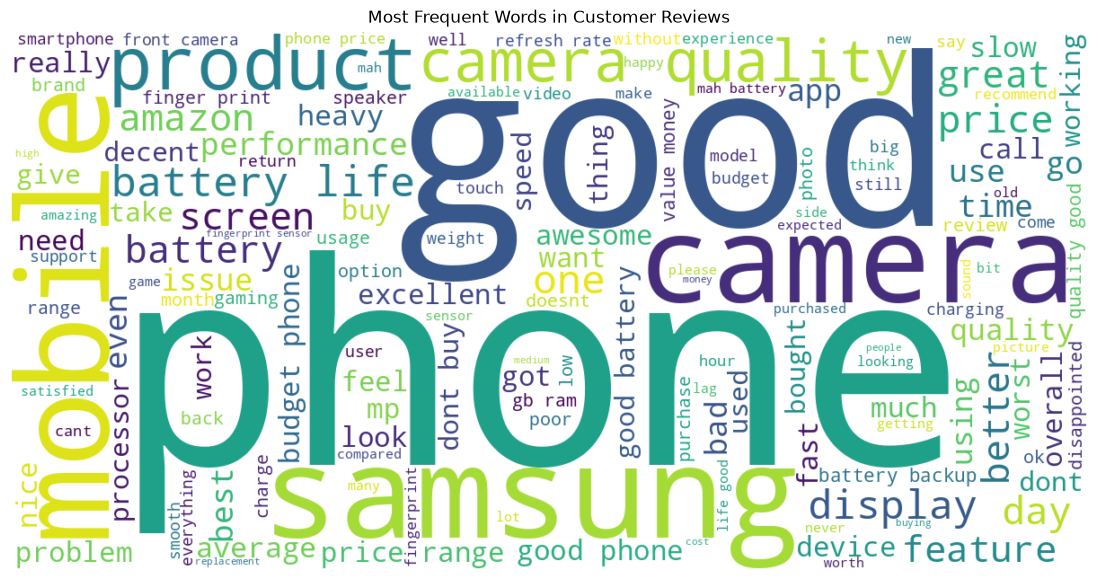

In [61]:
#Generate overall Word Cloud
all_text = ' '.join(
    df['cleaned_text']
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=150
).generate(all_text)

plt.figure(figsize=(15,7))

plt.imshow(
    wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    "Most Frequent Words in Customer Reviews"
)

plt.show()

In [62]:
#TF-IDF Vectorization
tfidf = TfidfVectorizer(
    max_features=3000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True
)

In [63]:
#Apply TF-IDF
tfidf_matrix = tfidf.fit_transform(
    df['cleaned_text']
)

print("TF-IDF Matrix Shape:")
print(tfidf_matrix.shape)

TF-IDF Matrix Shape:
(1440, 3000)


In [64]:
#Get TF-IDF feature names
tfidf_features = tfidf.get_feature_names_out()

print("Number of TF-IDF features:")
print(len(tfidf_features))

print("\nFirst 50 features:")
print(tfidf_features[:50])

Number of TF-IDF features:
3000

First 50 features:
['aap' 'able' 'able connect' 'able hear' 'able return' 'absolutely'
 'accept' 'acceptable' 'access' 'according' 'according price' 'accurate'
 'action' 'activity' 'actual' 'actually' 'ad' 'adapter' 'adaptive' 'add'
 'added' 'additional' 'address' 'advantage' 'advertised' 'advertising'
 'advice' 'advise' 'affordable' 'affordable phone' 'affordable price'
 'age' 'aged' 'ago' 'agreed' 'ahead' 'airtel' 'alarm' 'allow' 'allow use'
 'allowing' 'allows' 'almost' 'almost hour' 'almost month' 'along' 'alot'
 'already' 'also' 'also camera']


In [65]:
#Convert TF-IDF into DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_features
)

tfidf_df.head()

,aap,able,able connect,able hear,able return,absolutely,accept,acceptable,access,according,...,पन,बत,बह,मर,यत,यह,लम,शन,सर,ज़न
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [66]:
#Create model-ready dataset
engineered_features = df[
    [
        'review_length',
        'word_count',
        'character_count',
        'unique_word_count',
        'average_word_length',
        'sentence_count',
        'exclamation_count',
        'question_count',
        'hashtag_count',
        'uppercase_word_count',
        'vader_negative_score',
        'vader_neutral_score',
        'vader_positive_score',
        'vader_compound_score'
    ]
].reset_index(drop=True)

In [67]:
#Now combine them with TF-IDF
model_dataset = pd.concat(
    [
        engineered_features,
        tfidf_df
    ],
    axis=1
)

In [68]:
#Add target
model_dataset['sentiment'] = (
    df['sentiment'].values
)

In [69]:
model_dataset.head()

,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,...,बत,बह,मर,यत,यह,लम,शन,सर,ज़न,sentiment
0,76,10,76,6,8.666667,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Negative
1,61,11,61,5,6.000000,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Neutral
2,411,67,411,33,6.638889,3,0,1,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Positive
3,394,72,394,34,5.054054,13,0,0,0,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Negative
4,209,34,209,25,5.296296,4,0,0,0,9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Negative


In [70]:
#Create final cleaned readable dataset
cleaned_dataset = df[
    [
        'title',
        'rating',
        'body',
        'review_text',
        'cleaned_text',
        'sentiment',
        'review_length',
        'word_count',
        'character_count',
        'unique_word_count',
        'average_word_length',
        'sentence_count',
        'exclamation_count',
        'question_count',
        'hashtag_count',
        'uppercase_word_count',
        'vader_negative_score',
        'vader_neutral_score',
        'vader_positive_score',
        'vader_compound_score'
    ]
].copy()

In [71]:
#View final cleaned dataset
cleaned_dataset.head(10)

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,Horrible product,1,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...,Negative,76,10,76,6,8.666667,1,0,0,0,0,0.463,0.537,0.000,-0.7841
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low,Neutral,61,11,61,5,6.000000,1,0,0,0,0,0.319,0.681,0.000,-0.4956
2,Overall,4,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...,Positive,411,67,411,33,6.638889,3,0,1,0,1,0.076,0.843,0.081,0.1027
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...,Negative,394,72,394,34,5.054054,13,0,0,0,2,0.209,0.770,0.021,-0.9162
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...,Negative,209,34,209,25,5.296296,4,0,0,0,9,0.235,0.765,0.000,-0.8033
5,Too much lagging and slow,1,I will never purchase Samsung phones. Phone is...,Too much lagging and slow I will never purchas...,much lagging slow never purchase samsung phone...,Negative,128,23,128,11,5.400000,3,0,0,0,0,0.318,0.682,0.000,-0.7506
6,Worst samsung mobile ever,1,This is worst samsung mobile I have seen from ...,Worst samsung mobile ever This is worst samsun...,worst samsung mobile ever worst samsung mobile...,Negative,205,37,205,17,5.260870,4,0,0,0,0,0.193,0.753,0.054,-0.7845
7,कैसा दिखाते है उसका 10 % भी नही,1,मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बत...,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,कैसा दिखाते है उसका भी नही मोबाइल का कैमरा बिल...,Negative,167,37,167,23,3.787879,1,0,0,0,1,0.000,1.000,0.000,0.0000
8,Slow performance,1,The phone hangs a lot and is very slow. I rece...,Slow performance The phone hangs a lot and is ...,slow performance phone hang lot slow received ...,Negative,105,19,105,8,6.300000,2,0,0,0,0,0.000,1.000,0.000,0.0000
9,Don’t buy from Amazon.,1,Very poor quality camera .Found box seal damag...,Don’t buy from Amazon. Very poor quality camer...,buy amazon poor quality camera found box seal ...,Negative,210,32,210,20,6.000000,7,0,0,0,0,0.236,0.579,0.185,-0.6361


In [72]:
#Final missing-value check
print("Missing Values in Final Dataset:")
print(cleaned_dataset.isnull().sum())

Missing Values in Final Dataset:
title                   0
rating                  0
body                    0
review_text             0
cleaned_text            0
sentiment               0
review_length           0
word_count              0
character_count         0
unique_word_count       0
average_word_length     0
sentence_count          0
exclamation_count       0
question_count          0
hashtag_count           0
uppercase_word_count    0
vader_negative_score    0
vader_neutral_score     0
vader_positive_score    0
vader_compound_score    0
dtype: int64


In [73]:
#Final duplicate check
print(
    "Duplicate Rows:",
    cleaned_dataset.duplicated().sum()
)

Duplicate Rows: 0


In [74]:
#Final dataset shape
print(
    "Final Cleaned Dataset Shape:",
    cleaned_dataset.shape
)

Final Cleaned Dataset Shape: (1440, 20)


In [75]:
#Save cleaned dataset to csv
cleaned_dataset.to_csv(
    "cleaned_sentiment_dataset.csv",
    index=False
)

print(
    "Cleaned dataset saved as "
    "'cleaned_sentiment_dataset.csv'"
)

Cleaned dataset saved as 'cleaned_sentiment_dataset.csv'


In [76]:
#Save TF-IDF features
tfidf_df.to_csv(
    "tfidf_features.csv",
    index=False
)

print(
    "TF-IDF features saved successfully."
)

TF-IDF features saved successfully.


In [77]:
#Save model-ready dataset
model_dataset.to_csv(
    "model_ready_dataset.csv",
    index=False
)

print(
    "Model-ready dataset saved successfully."
)

Model-ready dataset saved successfully.


In [78]:
#Save TF-IDF vocabulary
vocabulary = pd.DataFrame({
    'feature': tfidf.get_feature_names_out()
})

vocabulary.to_csv(
    "tfidf_vocabulary.csv",
    index=False
)

print(
    "TF-IDF vocabulary saved successfully."
)

TF-IDF vocabulary saved successfully.


In [79]:
#Final project summary
print("=" * 70)
print("        NLP SENTIMENT ANALYSIS - EDA SUMMARY")
print("=" * 70)

print("\nOriginal/Current Number of Reviews:")
print(len(df))

print("\nFinal Cleaned Dataset Shape:")
print(cleaned_dataset.shape)

print("\nNumber of TF-IDF Features:")
print(tfidf_df.shape[1])

print("\nMissing Values:")
print(cleaned_dataset.isnull().sum().sum())

print("\nDuplicate Rows:")
print(cleaned_dataset.duplicated().sum())

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

print("\nEngineered Features:")
for feature in feature_columns:
    print("-", feature)

print("\nTF-IDF Matrix Shape:")
print(tfidf_matrix.shape)

print("\nFiles Generated:")
print("1. cleaned_sentiment_dataset.xlsx")
print("2. tfidf_features.csv")
print("3. model_ready_dataset.csv")
print("4. tfidf_vocabulary.csv")

print("\nEDA + NLP preprocessing completed successfully!")
print("=" * 70)

        NLP SENTIMENT ANALYSIS - EDA SUMMARY

Original/Current Number of Reviews:
1440

Final Cleaned Dataset Shape:
(1440, 20)

Number of TF-IDF Features:
3000

Missing Values:
0

Duplicate Rows:
0

Sentiment Distribution:
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

Engineered Features:
- review_length
- word_count
- character_count
- unique_word_count
- average_word_length
- sentence_count
- exclamation_count
- question_count
- hashtag_count
- uppercase_word_count
- vader_negative_score
- vader_neutral_score
- vader_positive_score
- vader_compound_score

TF-IDF Matrix Shape:
(1440, 3000)

Files Generated:
1. cleaned_sentiment_dataset.xlsx
2. tfidf_features.csv
3. model_ready_dataset.csv
4. tfidf_vocabulary.csv

EDA + NLP preprocessing completed successfully!


Modle Building And Evaluation

In [80]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,classification_report,f1_score


In [81]:
df=pd.read_excel('cleaned_sentiment_dataset.xlsx')
df.head()

,title,rating,body,review_text,cleaned_text,sentiment,review_length,word_count,character_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,uppercase_word_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,Horrible product,1,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...,horrible product disappointed overall performa...,Negative,76,10,76,6,8.666667,1,0,0,0,0,0.463,0.537,0.000,-0.7841
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Camera quality is not like 48 megapixel Camera...,camera quality like megapixel camera quality low,Neutral,61,11,61,5,6.000000,1,0,0,0,0,0.319,0.681,0.000,-0.4956
2,Overall,4,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt...",overall got mobile launch datebattery must app...,Positive,411,67,411,33,6.638889,3,0,1,0,1,0.076,0.843,0.081,0.1027
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...,big doesnt work ghz wifi frequency ghz old sch...,Negative,394,72,394,34,5.054054,13,0,0,0,2,0.209,0.770,0.021,-0.9162
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...,put money somewhere else worth buyingfaulty so...,Negative,209,34,209,25,5.296296,4,0,0,0,9,0.235,0.765,0.000,-0.8033


In [82]:
#Check target larbel distribution
print(df['sentiment'].value_counts())

sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


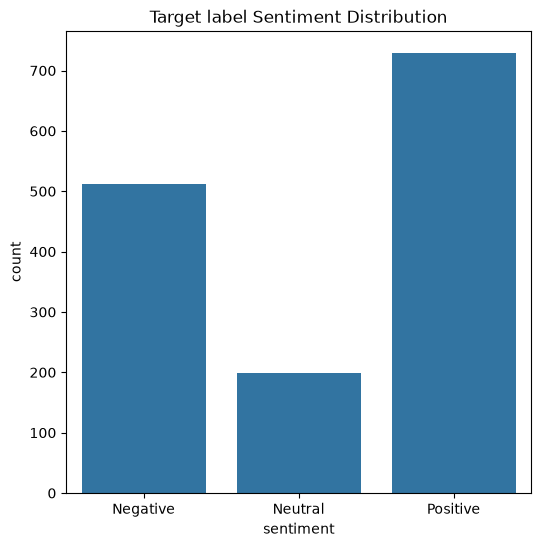

In [83]:
#Visualize
plt.figure(figsize=(6,6))

sns.countplot(
    data=df,
    x='sentiment'
)

plt.title("Target label Sentiment Distribution")

plt.show()

In [84]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load sample data
iris = load_iris()
X = iris.data
y = iris.target

# Now this will work
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [86]:
X_train,X_test,y_train,y_test=train_test_split(X,
                                               y,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=y
                                              )

#EXPERIMENT 1 : TF-IDF
#Cleaned Text
#         ↓
#TF-IDF
#         ↓
#ML Models

In [87]:
print(df.columns)

Index(['title', 'rating', 'body', 'review_text', 'cleaned_text', 'sentiment',
       'review_length', 'word_count', 'character_count', 'unique_word_count',
       'average_word_length', 'sentence_count', 'exclamation_count',
       'question_count', 'hashtag_count', 'uppercase_word_count',
       'vader_negative_score', 'vader_neutral_score', 'vader_positive_score',
       'vader_compound_score'],
      dtype='str')


In [88]:
# Run this to see the exact names of your columns
print(list(df.columns))

['title', 'rating', 'body', 'review_text', 'cleaned_text', 'sentiment', 'review_length', 'word_count', 'character_count', 'unique_word_count', 'average_word_length', 'sentence_count', 'exclamation_count', 'question_count', 'hashtag_count', 'uppercase_word_count', 'vader_negative_score', 'vader_neutral_score', 'vader_positive_score', 'vader_compound_score']


In [89]:
# Step 1: Print your columns and their index numbers
for index, column_name in enumerate(df.columns):
    print(f"Index [{index}]: {column_name}")

Index [0]: title
Index [1]: rating
Index [2]: body
Index [3]: review_text
Index [4]: cleaned_text
Index [5]: sentiment
Index [6]: review_length
Index [7]: word_count
Index [8]: character_count
Index [9]: unique_word_count
Index [10]: average_word_length
Index [11]: sentence_count
Index [12]: exclamation_count
Index [13]: question_count
Index [14]: hashtag_count
Index [15]: uppercase_word_count
Index [16]: vader_negative_score
Index [17]: vader_neutral_score
Index [18]: vader_positive_score
Index [19]: vader_compound_score


In [90]:
# Step 2: Put your column index numbers here
text_index = 0  # <-- Change this to your text column's number
target_index = 1  # <-- Change this to your target column's number

X = df.iloc[:, text_index]
y = df.iloc[:, target_index]

# Step 3: Run train_test_split successfully
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Successfully split the data!")

Successfully split the data!


In [91]:
#Applying TF-IDF
tfidf=TfidfVectorizer(
    max_features=3000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1,2),
    sublinear_tf=True
)

X_train_tfidf=tfidf.fit_transform(X_train)

X_test_tfidf=tfidf.transform(X_test)

In [92]:
#Logistic Regression
logistic_model=LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

#Train the model
logistic_model.fit(X_train_tfidf,y_train)

#predict the model
y_predict_logistic=logistic_model.predict(X_test_tfidf)


In [93]:
# Logistic model evaluation
print('The precision score is:', precision_score(y_test, y_predict_logistic, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, y_predict_logistic))
print('The recall_score is:', recall_score(y_test, y_predict_logistic, average='weighted'))
print('The F1 score is:', f1_score(y_test, y_predict_logistic, average='weighted', zero_division=0))

The precision score is: 0.514083660529739
The accuracy score is: 0.5138888888888888
The recall_score is: 0.5138888888888888
The F1 score is: 0.5128234668980651


In [94]:
#Naive Bayes
from sklearn.naive_bayes import MultinomialNB
nb_model=MultinomialNB(
)

nb_model.fit(X_train_tfidf,y_train)

#predict the model
nb_model_pred=nb_model.predict(X_test_tfidf)

In [95]:
# Evaluation of the model

print('The precision score is:', precision_score(y_test, nb_model_pred, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, nb_model_pred))
print('The recall_score is:', recall_score(y_test, nb_model_pred, average='weighted'))
print('The F1 score is:', f1_score(y_test, nb_model_pred, average='weighted', zero_division=0))

The precision score is: 0.49079520697167756
The accuracy score is: 0.53125
The recall_score is: 0.53125
The F1 score is: 0.46296209693923235


In [96]:
#Linear svm
from sklearn.svm import LinearSVC

svm_model=LinearSVC(
    random_state=42
)

#train the model
svm_model.fit(X_train_tfidf,y_train)

#predict the model
y_pred_svm=svm_model.predict(X_test_tfidf)

In [97]:
print('The precision score is:', precision_score(y_test, y_pred_svm, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, y_pred_svm))
print('The recall_score is:', recall_score(y_test, y_pred_svm, average='weighted'))
print('The F1 score is:', f1_score(y_test, y_pred_svm, average='weighted', zero_division=0))

The precision score is: 0.47636319815238576
The accuracy score is: 0.5
The recall_score is: 0.5
The F1 score is: 0.47722602902655686


In [98]:
# Create metrics comparison table
data = {
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes', 'Linear SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_predict_logistic),
        accuracy_score(y_test, nb_model_pred),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_predict_logistic, average='weighted', zero_division=0),
        precision_score(y_test, nb_model_pred, average='weighted', zero_division=0),
        precision_score(y_test, y_pred_svm, average='weighted', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_predict_logistic, average='weighted', zero_division=0),
        recall_score(y_test, nb_model_pred, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_svm, average='weighted', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_predict_logistic, average='weighted', zero_division=0),
        f1_score(y_test, nb_model_pred, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_svm, average='weighted', zero_division=0)
    ]
}

df_comparison = pd.DataFrame(data)

# Display table
print("Model Comparison Table ")
display(df_comparison)

# Declare best model
best_model = df_comparison.loc[df_comparison['F1 Score'].idxmax(), 'Model']
print(f"\nBest Model without engineered features: {best_model}")

Model Comparison Table 


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.513889,0.514084,0.513889,0.512823
1,Multinomial Naive Bayes,0.531250,0.490795,0.531250,0.462962
2,Linear SVM,0.500000,0.476363,0.500000,0.477226



Best Model without engineered features: Logistic Regression


  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\users\\girir\\anaconda3\\lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSans.ttf'
Consider using the `--user` option or check the permissions.



  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp313-cp313-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.

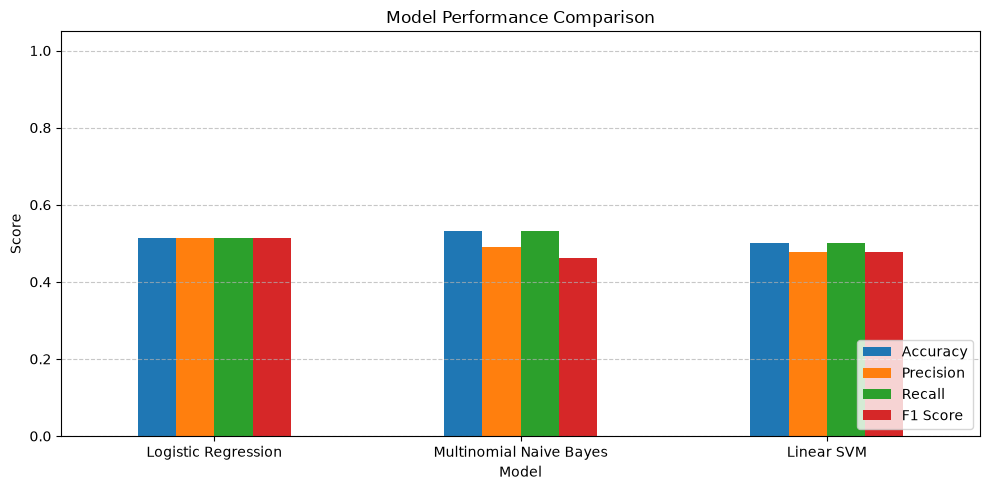

In [99]:
plot_df = df_comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]]

# Plot bar chart
plot_df.plot(kind="bar", figsize=(10, 5))

# Plot customization
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [100]:
#Logistic regression
cr=classification_report(y_test,y_predict_logistic)
print('The classification report for the logistic model is:',cr)

The classification report for the logistic model is:               precision    recall  f1-score   support

           1       0.65      0.71      0.68        77
           2       0.29      0.32      0.30        25
           3       0.47      0.40      0.43        40
           4       0.35      0.35      0.35        62
           5       0.60      0.56      0.58        84

    accuracy                           0.51       288
   macro avg       0.47      0.47      0.47       288
weighted avg       0.51      0.51      0.51       288



In [101]:
cm=confusion_matrix(y_test,y_predict_logistic)
print('confusion matrix is:\n',cm)

confusion matrix is:
 [[55 12  4  3  3]
 [10  8  3  2  2]
 [10  4 16  6  4]
 [ 7  2  9 22 22]
 [ 3  2  2 30 47]]


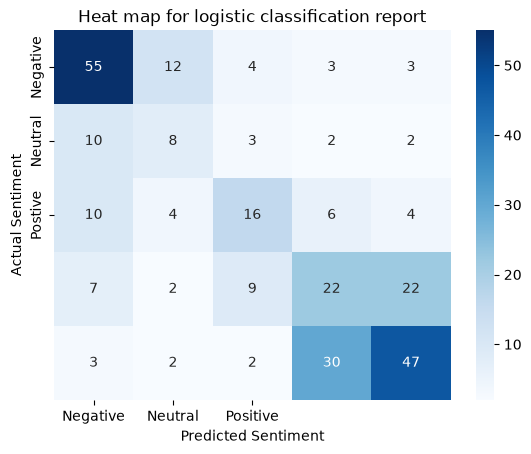

In [102]:
sns.heatmap(
    cm,
    annot=True,
    cmap='Blues',
    fmt='d',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Postive']
)
plt.title('Heat map for logistic classification report')
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.show()

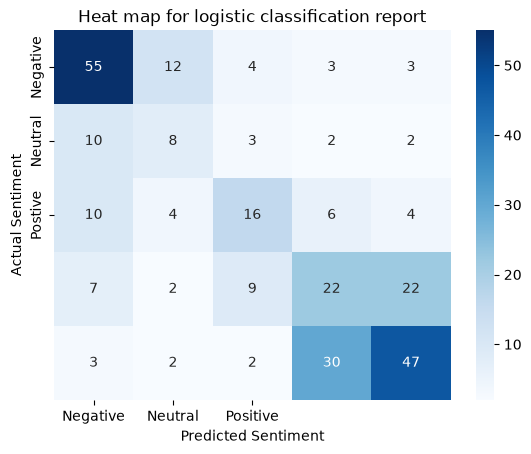

In [103]:
sns.heatmap(
    cm,
    annot=True,
    cmap='Blues',
    fmt='d',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Postive']
)
plt.title('Heat map for logistic classification report')
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.show()

In [104]:
cm1=confusion_matrix(y_test,y_pred_svm)
print('The confusion matrix is \n:',cm1)

The confusion matrix is 
: [[58  3  4  4  8]
 [12  3  2  6  2]
 [12  2 12  8  6]
 [ 7  1  6 15 33]
 [ 3  0  1 24 56]]


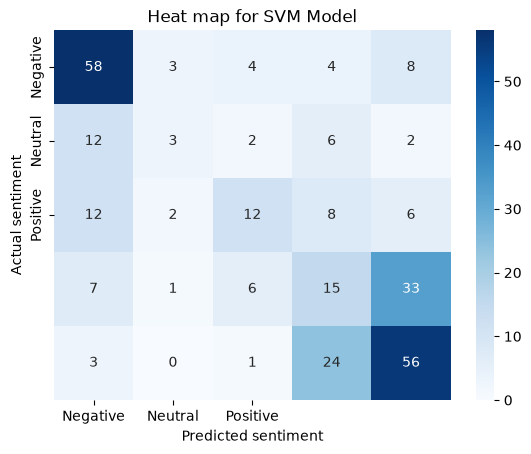

In [105]:
sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Heat map for SVM Model')
plt.ylabel('Actual sentiment')
plt.xlabel('Predicted sentiment')
plt.show()

#EXPERIMENT 2 — TF-IDF +Eng Features
#Cleaned Text
#     ↓
#TF-IDF
#    ↓
#ML Models

In [106]:
engineered_features = [
    'review_length',
    'word_count',
    'unique_word_count',
    'average_word_length',
    'sentence_count',
    'exclamation_count',
    'question_count',
    'hashtag_count',
    'vader_negative_score',
    'vader_neutral_score',
    'vader_positive_score',
    'vader_compound_score'
]
df[engineered_features].head()

,review_length,word_count,unique_word_count,average_word_length,sentence_count,exclamation_count,question_count,hashtag_count,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score
0,76,10,6,8.666667,1,0,0,0,0.463,0.537,0.000,-0.7841
1,61,11,5,6.000000,1,0,0,0,0.319,0.681,0.000,-0.4956
2,411,67,33,6.638889,3,0,1,0,0.076,0.843,0.081,0.1027
3,394,72,34,5.054054,13,0,0,0,0.209,0.770,0.021,-0.9162
4,209,34,25,5.296296,4,0,0,0,0.235,0.765,0.000,-0.8033


In [107]:
#split the features
X_text=df['cleaned_text']
X_eng=df[engineered_features]
y=df['sentiment']

In [108]:
X_text_train,X_text_test,X_eng_train,X_eng_test,y_train,y_test=train_test_split(X_text,
                                                                                X_eng,
                                                                                y,
                                                                                test_size=0.2,
                                                                                random_state=42,
                                                                                stratify=y)

In [109]:
scaler=StandardScaler()

X_eng_train_scaled=scaler.fit_transform(X_eng_train)
X_eng_test_scaled=scaler.transform(X_eng_test)

In [110]:
#create vectorizer for cleaned text
tfidf=TfidfVectorizer(
    max_features=3000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1,2),
    sublinear_tf=True
)

X_train_tfidf=tfidf.fit_transform(X_text_train)
X_test_tfidf=tfidf.transform(X_text_test)

In [111]:
#combine the TF-IDF and engineered_features

X_train_combined=hstack([
    X_train_tfidf,
    X_eng_train_scaled
])

X_test_combined=hstack([
    X_test_tfidf,
    X_eng_test_scaled
])

In [112]:
#Logistic regression
from sklearn.linear_model import LogisticRegression

lr_model_eng=LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

lr_model_eng.fit(X_train_combined,y_train)

#Predict the model
lr_y_pred=lr_model_eng.predict(X_test_combined)


In [113]:
#Model evaluation

print('The precision score is:', precision_score(y_test, lr_y_pred, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, lr_y_pred))
print('The recall_score is:', recall_score(y_test, lr_y_pred, average='weighted'))
print('The F1 score is:', f1_score(y_test, lr_y_pred, average='weighted', zero_division=0))

The precision score is: 0.7271048999309868
The accuracy score is: 0.7152777777777778
The recall_score is: 0.7152777777777778
The F1 score is: 0.7208206844834751


In [114]:
#simple linear SVM
svm_model=LinearSVC(
    max_iter=5000,
    random_state=42
)

svm_model.fit(X_train_combined,y_train)

#Predict the model
y_pred_lsvm=svm_model.predict(X_test_combined)

In [115]:
#Model evaluation

print('The precision score is:', precision_score(y_test, y_pred_lsvm, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, y_pred_lsvm))
print('The recall_score is:', recall_score(y_test, y_pred_lsvm, average='weighted'))
print('The F1 score is:', f1_score(y_test, y_pred_lsvm, average='weighted', zero_division=0))

The precision score is: 0.731153048949687
The accuracy score is: 0.7604166666666666
The recall_score is: 0.7604166666666666
The F1 score is: 0.7377578312706832


In [116]:
# Create metrics comparison table
data = {
    'Model': ['Logistic Regression','Linear SVM'],
    'Accuracy': [
        accuracy_score(y_test, lr_y_pred),
        accuracy_score(y_test, y_pred_lsvm)
    ],
    'Precision': [
        precision_score(y_test, lr_y_pred, average='weighted', zero_division=0),
        precision_score(y_test, y_pred_lsvm, average='weighted', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, lr_y_pred, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_lsvm, average='weighted', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, lr_y_pred, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_lsvm, average='weighted', zero_division=0)
    ]
}

df_comparison = pd.DataFrame(data)

# Display table
print("Model Comparison Table with Eng Features")
display(df_comparison)

# Declare best model
best_model = df_comparison.loc[df_comparison['F1 Score'].idxmax(), 'Model']
print(f"\nBest Model with engineered features: {best_model}")

Model Comparison Table with Eng Features


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.715278,0.727105,0.715278,0.720821
1,Linear SVM,0.760417,0.731153,0.760417,0.737758



Best Model with engineered features: Linear SVM


In [117]:
#Linear SVM
cm_svm=confusion_matrix(y_test,y_pred_lsvm)
cm_svm

array([[ 84,   4,  14],
       [ 17,   7,  16],
       [ 12,   6, 128]])

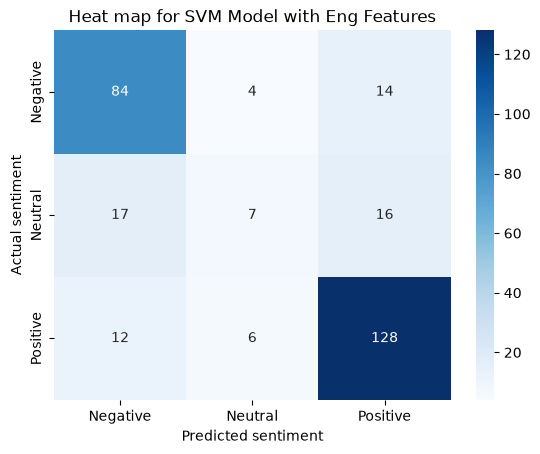

In [118]:
sns.heatmap(
    cm_svm,
    annot=True,
    cmap='Blues',
    fmt='d',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Heat map for SVM Model with Eng Features')
plt.ylabel('Actual sentiment')
plt.xlabel('Predicted sentiment')
plt.show()


#EXPERIMENT 3 — Word2vec
#Cleaned Text
#    ↓
#Word2vec
#    ↓
#ML Models

In [119]:
!pip install gensim

In [120]:
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier


import numpy as np
from sklearn.preprocessing import MinMaxScaler


In [121]:
X=df['cleaned_text']
y=df['sentiment']

In [122]:
x_train,x_test,y_train,y_test=train_test_split(X,
                                               y,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=y
                                              )

In [123]:
#Apply the word2vec for the cleaned text

sentences = [text.split() for text in x_train]

word2vec_model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

In [124]:
def review_to_vector(review):
    vectors = [
        word2vec_model.wv[word]
        for word in review.split()
        if word in word2vec_model.wv
    ]

    if not vectors:
        return np.zeros(word2vec_model.vector_size)

    return np.mean(vectors, axis=0)

In [125]:
#Apply to the train and test data
x_train_w2v = np.array([review_to_vector(review) for review in x_train])
x_test_w2v = np.array([review_to_vector(review) for review in x_test])

print(x_train_w2v.shape)
print(x_test_w2v.shape)

(1152, 100)
(288, 100)


In [126]:
scaler=MinMaxScaler()

x_train_w2v_scaled=scaler.fit_transform(x_train_w2v)
x_test_w2v_scaled=scaler.transform(x_test_w2v)

In [127]:
#Logistic regression
from sklearn.linear_model import LogisticRegression

lr_model_w2v=LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model_w2v.fit(x_train_w2v_scaled,y_train)

#Predict the model
lr_y_pred_w2v=lr_model_w2v.predict(x_test_w2v_scaled)

In [128]:
#Evaluation of the logistic model
print('The precision score is:', precision_score(y_test, lr_y_pred_w2v, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, lr_y_pred_w2v))
print('The recall_score is:', recall_score(y_test, lr_y_pred_w2v, average='weighted'))
print('The F1 score is:', f1_score(y_test, lr_y_pred_w2v, average='weighted', zero_division=0))

The precision score is: 0.646465492838797
The accuracy score is: 0.5972222222222222
The recall_score is: 0.5972222222222222
The F1 score is: 0.6158279835885965


In [129]:
#Linear svm
from sklearn.svm import LinearSVC

svm_model_w2v=LinearSVC(
    max_iter=5000,
    random_state=42
)

svm_model_w2v.fit(x_train_w2v_scaled,y_train)

#predict the model
y_pred_svm_w2v=svm_model_w2v.predict(x_test_w2v_scaled)

In [130]:
#Evaluation metrix
print('The precision score is:', precision_score(y_test, y_pred_svm_w2v, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, y_pred_svm_w2v))
print('The recall_score is:', recall_score(y_test, y_pred_svm_w2v, average='weighted'))
print('The F1 score is:', f1_score(y_test, y_pred_svm_w2v, average='weighted', zero_division=0))

The precision score is: 0.6130306659152812
The accuracy score is: 0.7118055555555556
The recall_score is: 0.7118055555555556
The F1 score is: 0.6587335504002171


In [131]:
#Random Forest
rf_model_w2v=RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

rf_model_w2v.fit(x_train_w2v_scaled,y_train)

#predict the model
y_pred_rf_w2v=rf_model_w2v.predict(x_test_w2v_scaled)

In [132]:
#Evaluation of the matrix
print('The precision score is:', precision_score(y_test, y_pred_rf_w2v, average='weighted', zero_division=0))
print('The accuracy score is:', accuracy_score(y_test, y_pred_rf_w2v))
print('The recall_score is:', recall_score(y_test, y_pred_rf_w2v, average='weighted'))
print('The F1 score is:', f1_score(y_test, y_pred_rf_w2v, average='weighted'))

The precision score is: 0.5945266336461592
The accuracy score is: 0.6076388888888888
The recall_score is: 0.6076388888888888
The F1 score is: 0.5991999973154274


In [133]:
#Comparision of the models

data={
    'Model':['Logistic Regression','Linear SVM','Random Forest'],
    'Accuracy':[
        accuracy_score(y_test,lr_y_pred_w2v),
        accuracy_score(y_test,y_pred_svm_w2v),
        accuracy_score(y_test,y_pred_rf_w2v)
    ],
    'Precision':[
        precision_score(y_test,lr_y_pred_w2v,average='weighted',zero_division=0),
        precision_score(y_test,y_pred_svm_w2v,average='weighted',zero_division=0),
        precision_score(y_test,y_pred_rf_w2v,average='weighted',zero_division=0)
    ],
    'Recall':[
        recall_score(y_test,lr_y_pred_w2v,average='weighted',zero_division=0),
        recall_score(y_test,y_pred_svm_w2v,average='weighted',zero_division=0),
        recall_score(y_test,y_pred_rf_w2v,average='weighted',zero_division=0),
    ],
    'F1 Score':[
        f1_score(y_test,lr_y_pred_w2v,average='weighted',zero_division=0),
        f1_score(y_test,y_pred_svm_w2v,average='weighted',zero_division=0),
        f1_score(y_test,y_pred_rf_w2v,average='weighted',zero_division=0)
    ]
}

df_comparison=pd.DataFrame(data)

#Display the data
print('Model Comparison Table with Word2Vec')
display(df_comparison)

#declare the best model

best_model=df_comparison.loc[df_comparison['F1 Score'].idxmax(),'Model']
print(f'\nBest Model with Word2Vec: {best_model}')

Model Comparison Table with Word2Vec


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.597222,0.646465,0.597222,0.615828
1,Linear SVM,0.711806,0.613031,0.711806,0.658734
2,Random Forest,0.607639,0.594527,0.607639,0.599200



Best Model with Word2Vec: Linear SVM


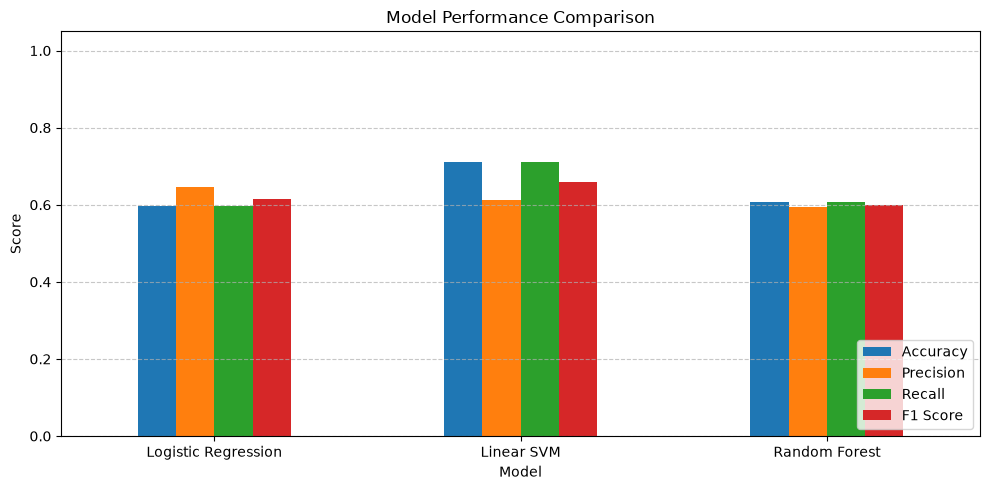

In [134]:
#plot the comparion

plot_df=df_comparison.set_index('Model')[['Accuracy','Precision','Recall','F1 Score']]

plot_df.plot(kind="bar",figsize=(10,5))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0,1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

In [135]:
#confusion matrix for the logistic

cm=confusion_matrix(y_test,lr_y_pred_w2v)
cm

array([[75, 18,  9],
       [14,  8, 18],
       [22, 35, 89]])

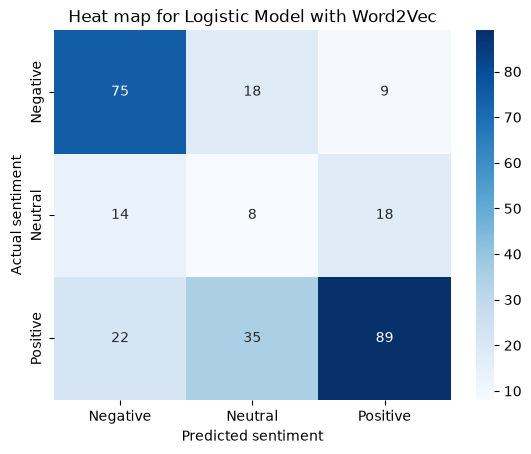

In [136]:
sns.heatmap(
    cm,
    annot=True,
    cmap='Blues',
    fmt='d',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Heat map for Logistic Model with Word2Vec')
plt.ylabel('Actual sentiment')
plt.xlabel('Predicted sentiment')
plt.show()

#EXPERIMENT 4 — Word2vec
#Cleaned Text
#    ↓
#Word2vec
#    ↓
#DL Models

In [137]:
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,LSTM,Dense,Masking,Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

In [138]:
X=df['cleaned_text']
y=df['sentiment']

In [139]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,
                                               y,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=y
                                              )
le=LabelEncoder()

y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

In [140]:
#create word2vec object
sentences=[text.split() for text in X_train]
word2vec_modeld=Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

In [141]:
def review_to_vector(review):
  vectors=[
      word2vec_modeld.wv[word]
      for word in review.split()
      if word in word2vec_modeld.wv
  ]

  if not vectors:
    return np.empty((0,100))

  return np.array(vectors)

In [142]:
#Apply to the train,test data
X_train_w2=[review_to_vector(review) for review in X_train]
X_test_w2=[review_to_vector(review) for review in X_test]

In [143]:
#check the distribution of the sequence length
lenghts=[len(seq)for seq in X_train_w2]
np.percentile(lenghts,[50,60,75,90,95,99])

array([ 26.  ,  29.  ,  36.  ,  49.  ,  66.45, 104.  ])

In [144]:
max_len=68
vector_size=100

In [145]:
def pad_sequences(sequences,max_len,vector_size):
  padded=np.zeros((len(sequences),max_len,vector_size))

  for i,seq in enumerate(sequences):
    length=min(len(seq),max_len)
    padded[i,:length,:]=seq[:length]
  return padded

In [146]:
#pad training data
X_train_w2v_padded=pad_sequences(X_train_w2,max_len,vector_size)

#pad test data
X_test_w2v_padded=pad_sequences(X_test_w2,max_len,vector_size)

In [147]:
#Building RNN model
rnn_model = Sequential([
    Masking(mask_value=0.0, input_shape=(max_len, vector_size)),
    SimpleRNN(64, activation='tanh'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])
rnn_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

C:\Users\girir\anaconda3\Lib\site-packages\keras\src\layers\core\masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [148]:
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True
)

In [149]:
history_rnn=rnn_model.fit(
    X_train_w2v_padded,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping]

    )

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.4625 - loss: 1.1089 - val_accuracy: 0.4805 - val_loss: 0.9864
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.4625 - loss: 1.0575 - val_accuracy: 0.5195 - val_loss: 0.9622
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - accuracy: 0.4701 - loss: 1.0276 - val_accuracy: 0.5238 - val_loss: 0.9774
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 185ms/step - accuracy: 0.4875 - loss: 1.0214 - val_accuracy: 0.5281 - val_loss: 0.9809
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.5027 - loss: 1.0160 - val_accuracy: 0.5108 - val_loss: 0.9548
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.4767 - loss: 1.0147 - val_accuracy: 0.5411 - val_loss: 0.9801
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 15s 441ms/step - accuracy: 0.5060 - loss: 0.9902 - val_accuracy: 0.5152 - val_loss: 0.9720
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 177ms/step - accuracy: 0.5027 - loss: 1.0002 - val_accuracy: 0.5

In [150]:
#Predict the model
y_pred_rnn=rnn_model.predict(X_test_w2v_padded)
rnn_y_pred=np.argmax(y_pred_rnn,axis=1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step


In [151]:
print('The accuaracy of RNN is:',accuracy_score(y_test,rnn_y_pred))
print('The precision of RNN is:',precision_score(y_test,rnn_y_pred,average='weighted',zero_division=0))
print('The recall of RNN is:',recall_score(y_test,rnn_y_pred,average='weighted',zero_division=0))
print('The f1 score of RNN is:',f1_score(y_test,rnn_y_pred,average='weighted',zero_division=0))

The accuaracy of RNN is: 0.5138888888888888
The precision of RNN is: 0.42526771474139896
The recall of RNN is: 0.5138888888888888
The f1 score of RNN is: 0.4421645007201286


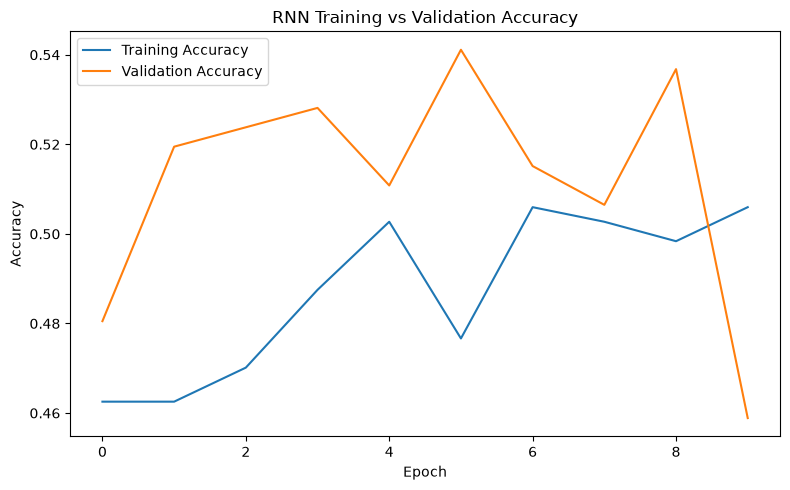

In [152]:
# RNN Accuracy Curve
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    history_rnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_rnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("RNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [153]:
cm=confusion_matrix(y_test,rnn_y_pred)
cm

array([[ 25,   0,  77],
       [  9,   0,  31],
       [ 23,   0, 123]])

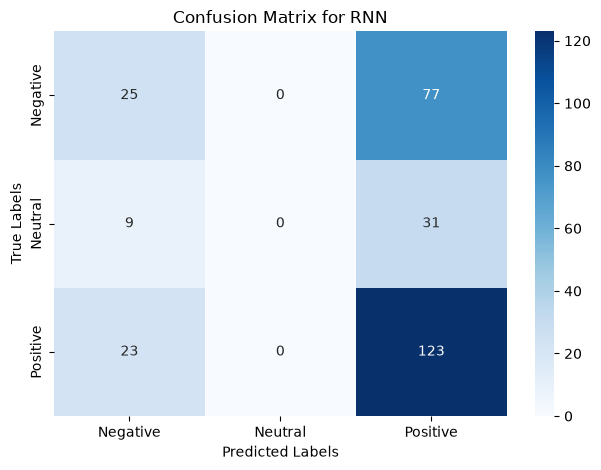

In [154]:
import seaborn as sns
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Confusion Matrix for RNN')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.tight_layout()
plt.show()


In [155]:
#LSTM Model
lstm_model=Sequential([
    Masking(mask_value=0.0,input_shape=(max_len,vector_size)),
    LSTM(64,activation='tanh'),
    Dropout(0.3),
    Dense(3,activation='softmax')
])

C:\Users\girir\anaconda3\Lib\site-packages\keras\src\layers\core\masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [156]:
lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
    )

In [157]:
early_stoppping=EarlyStopping(
    monitor='val_accuracy',
    patience=8,
    restore_best_weights=True
)

In [158]:
history_lstm=lstm_model.fit(
    X_train_w2v_padded,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 35s 703ms/step - accuracy: 0.4929 - loss: 1.0066 - val_accuracy: 0.5281 - val_loss: 0.9762
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 125ms/step - accuracy: 0.5027 - loss: 1.0036 - val_accuracy: 0.5281 - val_loss: 0.9702
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 11s 319ms/step - accuracy: 0.4864 - loss: 0.9997 - val_accuracy: 0.5238 - val_loss: 0.9741
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.5071 - loss: 0.9893 - val_accuracy: 0.5281 - val_loss: 0.9670
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 141ms/step - accuracy: 0.4995 - loss: 0.9874 - val_accuracy: 0.5238 - val_loss: 0.9691
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 337ms/step - accuracy: 0.5005 - loss: 0.9899 - val_accuracy: 0.5281 - val_loss: 0.9655


In [159]:
#Predict the model
y_pred_lstm=lstm_model.predict(X_test_w2v_padded)
lstm_y_pred=np.argmax(y_pred_lstm,axis=1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step


In [160]:
#Evaluation
print('The Accuarcy of LSTM is :',accuracy_score(y_test,lstm_y_pred))
print('The Precision of LSTM is :',precision_score(y_test,lstm_y_pred,average='weighted',zero_division=0, labels=np.unique(y_test)))
print('The Recall of LSTM is :',recall_score(y_test,lstm_y_pred,average='weighted',zero_division=0, labels=np.unique(y_test)))
print('The F1 Score of LSTM is :',f1_score(y_test,lstm_y_pred,average='weighted',zero_division=0, labels=np.unique(y_test)))

The Accuarcy of LSTM is : 0.5069444444444444
The Precision of LSTM is : 0.25699266975308643
The Recall of LSTM is : 0.5069444444444444
The F1 Score of LSTM is : 0.34107782898105476


In [161]:
cm=confusion_matrix(
    y_test,
    lstm_y_pred,
)
cm

array([[  0,   0, 102],
       [  0,   0,  40],
       [  0,   0, 146]])

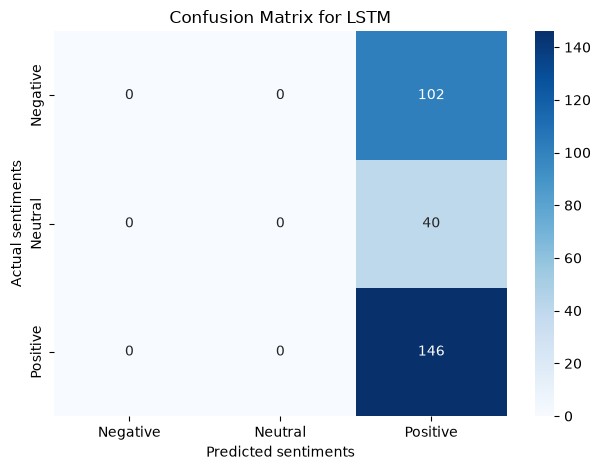

In [162]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Confusion Matrix for LSTM')
plt.xlabel('Predicted sentiments')
plt.ylabel('Actual sentiments')
plt.tight_layout()
plt.show()

In [163]:
df_comparision_results=pd.DataFrame({
    'Model':['RNN','LSTM'],
    'Accuracy':[accuracy_score(y_test,rnn_y_pred),accuracy_score(y_test,lstm_y_pred)],
    'Precision':[precision_score(y_test,rnn_y_pred,average='weighted',zero_division=0),
                 precision_score(y_test,lstm_y_pred,average='weighted',zero_division=0)],
    'Recall':[recall_score(y_test,rnn_y_pred,average='weighted',zero_division=0),
              recall_score(y_test,lstm_y_pred,average='weighted',zero_division=0)],
    'F1 Score':[f1_score(y_test,rnn_y_pred,average='weighted',zero_division=0),
                f1_score(y_test,lstm_y_pred,average='weighted',zero_division=0)]
})

display(df_comparision_results)

,Model,Accuracy,Precision,Recall,F1 Score
0,RNN,0.513889,0.425268,0.513889,0.442165
1,LSTM,0.506944,0.256993,0.506944,0.341078


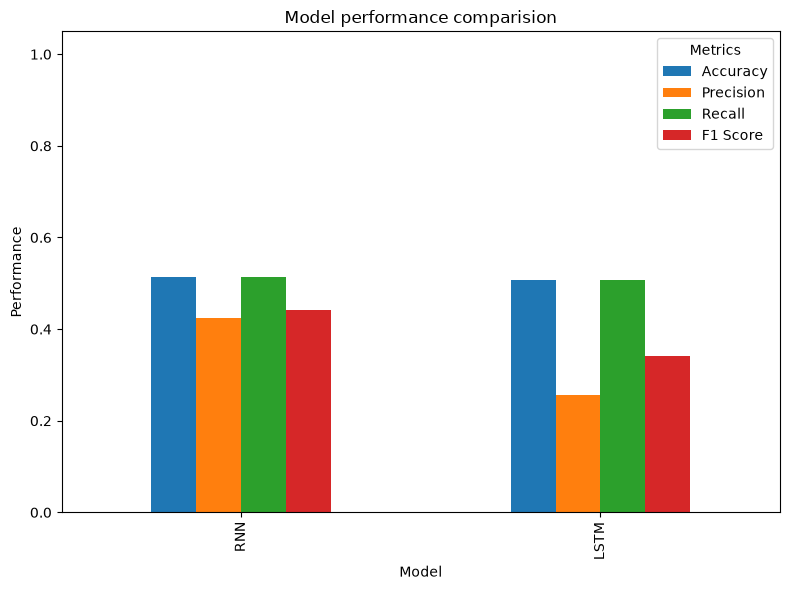

In [164]:
plot_df=df_comparision_results.set_index('Model')[['Accuracy','Precision','Recall','F1 Score']]

plot_df.plot(kind='bar',figsize=(8,6))

plt.title('Model performance comparision')
plt.xlabel('Model')
plt.ylim(0,1.05)
plt.ylabel('Performance')
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

#EXPERIMENT 5 — DistilBERT
#Cleaned Text
#    ↓
#DistilBERT
v

In [165]:
from torch.utils.data import DataLoader
from transformers import DistilBertTokenizer
import torch 
from torch.utils.data import Dataset
from torch.optim import AdamW


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification


In [166]:
X=df['cleaned_text']
y=df['sentiment']

In [167]:
X_train,X_test,y_train,y_test=train_test_split(X,
                                               y,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=y
                                              )
le=LabelEncoder()

y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

In [168]:
class SentimentDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = self.tokenizer(
            str(self.texts.iloc[index]),
            padding="max_length",
            truncation=True,
            max_length=self.max_length
        )

        return {
            "input_ids": torch.tensor(encoding["input_ids"]),
            "attention_mask": torch.tensor(encoding["attention_mask"]),
            "labels": torch.tensor(self.labels[index], dtype=torch.long)
        }

In [169]:
# Initialize the tokenizer
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# Create dataset instances
train_dataset = SentimentDataset(X_train, y_train, tokenizer)
test_dataset = SentimentDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [170]:
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [171]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [172]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW

# 1. Load or define your model first (make sure to set num_labels based on your target 'y')
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", num_labels=2
)

# 2. Now this will work because 'model' is defined!
optimizer = AdamW(model.parameters(), lr=2e-5)

print("Optimizer initialized successfully!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Optimizer initialized successfully!


In [173]:
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

In [174]:
import torch

print("Unique labels in y:", y.unique())
print("Total number of classes:", len(y.unique()))

Unique labels in y: <ArrowStringArray>
['Negative', 'Neutral', 'Positive']
Length: 3, dtype: str
Total number of classes: 3


In [175]:
from transformers import AutoModelForSequenceClassification

# Change 2 to match the actual number of unique classes you have!
num_classes = len(y.unique()) 

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", 
    num_labels=num_classes
)

print(f"Model updated to handle {num_classes} classes.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model updated to handle 3 classes.


In [176]:
# Reduce training dataset size for faster execution

MAX_SAMPLES = 2000

if len(train_dataset) > MAX_SAMPLES:
    train_dataset_small = torch.utils.data.Subset(
        train_dataset,
        range(MAX_SAMPLES)
    )
else:
    train_dataset_small = train_dataset

print("Training samples:", len(train_dataset_small))

Training samples: 1152


In [177]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset_small,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 144


In [198]:
from torch.utils.data import DataLoader, Subset

MAX_SAMPLES = 300

small_dataset = Subset(
    train_loader.dataset,
    range(min(MAX_SAMPLES, len(train_loader.dataset)))
)

train_loader = DataLoader(
    small_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

print("Training samples:", len(small_dataset))
print("Total batches:", len(train_loader))

Training samples: 300
Total batches: 38


In [199]:
import time
import torch

epochs = 1
start_time = time.time()

model.to(device)

model.train()
total_loss = 0 

for step, batch in enumerate(train_loader):

    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    print(
        f"Batch {step + 1}/{len(train_loader)} | "
        f"Loss: {loss.item():.4f} | "
        f"Time: {(time.time() - start_time):.1f}s"
    )

average_loss = total_loss / len(train_loader)

print("\nTraining completed!")
print(f"Average Loss: {average_loss:.4f}")
print(f"Total Time: {(time.time() - start_time) / 60:.2f} minutes")

Batch 1/38 | Loss: 1.1575 | Time: 24.3s
Batch 2/38 | Loss: 1.3453 | Time: 41.9s
Batch 3/38 | Loss: 1.3371 | Time: 69.0s
Batch 4/38 | Loss: 1.4326 | Time: 123.9s
Batch 5/38 | Loss: 1.1976 | Time: 134.9s
Batch 6/38 | Loss: 1.0567 | Time: 149.9s
Batch 7/38 | Loss: 1.1721 | Time: 166.2s
Batch 8/38 | Loss: 1.0134 | Time: 182.5s
Batch 9/38 | Loss: 1.2551 | Time: 197.5s
Batch 10/38 | Loss: 1.1048 | Time: 213.3s
Batch 11/38 | Loss: 1.4482 | Time: 229.1s
Batch 12/38 | Loss: 1.3515 | Time: 246.6s
Batch 13/38 | Loss: 1.3645 | Time: 262.2s
Batch 14/38 | Loss: 1.2999 | Time: 279.3s
Batch 15/38 | Loss: 1.3757 | Time: 294.7s
Batch 16/38 | Loss: 1.3876 | Time: 319.1s
Batch 17/38 | Loss: 1.1951 | Time: 365.2s
Batch 18/38 | Loss: 1.2972 | Time: 379.4s
Batch 19/38 | Loss: 1.1695 | Time: 394.1s
Batch 20/38 | Loss: 1.2939 | Time: 437.1s
Batch 21/38 | Loss: 1.0569 | Time: 492.7s
Batch 22/38 | Loss: 1.0407 | Time: 504.7s
Batch 23/38 | Loss: 1.3848 | Time: 532.3s
Batch 24/38 | Loss: 1.1442 | Time: 555.3s
Batc

In [200]:
model.eval()

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [201]:
y_pred = []
y_true = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        y_pred.extend(predictions.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

In [202]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.1388888888888889
Precision: 0.019290123456790122
Recall: 0.1388888888888889
F1 Score: 0.03387533875338753


C:\Users\girir\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [203]:
#confusion matrix
cm=confusion_matrix(y_true,y_pred)
cm

array([[  0, 102,   0],
       [  0,  40,   0],
       [  0, 146,   0]])

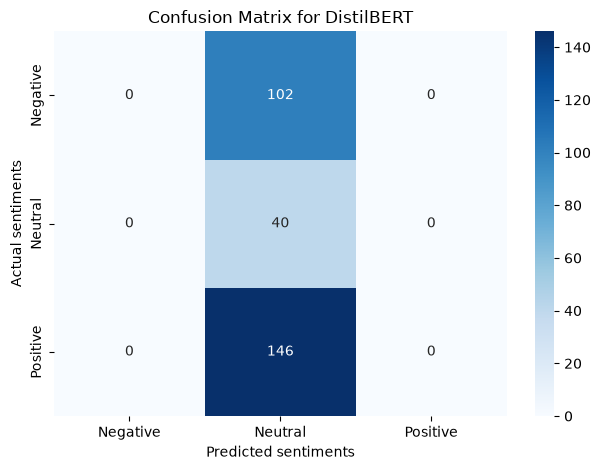

In [204]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative','Neutral','Positive'],
    yticklabels=['Negative','Neutral','Positive']
)
plt.title('Confusion Matrix for DistilBERT')
plt.xlabel('Predicted sentiments')
plt.ylabel('Actual sentiments')
plt.tight_layout()
plt.show()

In [205]:
print("LabelEncoder classes:", le.classes_)
print("y_test sample:", y_test[:10])
print("Logistic predictions:", y_predict_logistic[:10])
print("Naive Bayes predictions:", nb_model_pred[:10])
print("DistilBERT predictions:", y_pred[:10])

LabelEncoder classes: ['Negative' 'Neutral' 'Positive']
y_test sample: [2 0 2 0 1 2 2 0 2 0]
Logistic predictions: [5 1 5 2 1 4 5 1 4 2]
Naive Bayes predictions: [5 1 5 1 1 4 5 1 4 5]
DistilBERT predictions: [np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1)]


In [206]:
accuracy_score(y_test, y_predict_logistic)

0.04861111111111111

In [207]:
y_test:   [0, 1, 2]
lr_y_pred: ['Negative', 'Neutral', 'Positive']

In [208]:
print("LabelEncoder mapping:")

for index, label in enumerate(le.classes_):
    print(f"{label} = {index}")

LabelEncoder mapping:
Negative = 0
Neutral = 1
Positive = 2


In [209]:
import numpy as np

def convert_predictions(predictions):
    predictions = np.asarray(predictions)

    # Convert text labels into numeric labels
    if predictions.dtype.kind in ("U", "S", "O"):
        return le.transform(predictions)

    # Already numeric
    return predictions.astype(int)

In [210]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

all_experiments_data = [
    {
        "Experiment": "Exp 1: TF-IDF",
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(y_predict_logistic)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(y_predict_logistic),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 1: TF-IDF",
        "Model": "Multinomial Naive Bayes",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(nb_model_pred)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(nb_model_pred),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 1: TF-IDF",
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(y_pred_svm)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(y_pred_svm),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 2: TF-IDF + Eng Features",
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(lr_y_pred)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(lr_y_pred),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 2: TF-IDF + Eng Features",
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(y_pred_lsvm)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(y_pred_lsvm),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 3: Word2Vec",
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(lr_y_pred_w2v)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(lr_y_pred_w2v),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 3: Word2Vec",
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(y_pred_svm_w2v)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(y_pred_svm_w2v),
            average="weighted", zero_division=0
        ),
    },
    {
        "Experiment": "Exp 5: DistilBERT",
        "Model": "DistilBERT",
        "Accuracy": accuracy_score(
            y_test, convert_predictions(y_pred)
        ),
        "F1 Score": f1_score(
            y_test, convert_predictions(y_pred),
            average="weighted", zero_division=0
        ),
    }
]

df_overall_comparison = pd.DataFrame(all_experiments_data)

display(df_overall_comparison)

best_row_idx = df_overall_comparison["F1 Score"].idxmax()

best_model = df_overall_comparison.loc[
    best_row_idx, "Model"
]

print(f"Best model based on weighted F1 score: {best_model}")

,Experiment,Model,Accuracy,F1 Score
0,Exp 1: TF-IDF,Logistic Regression,0.048611,0.045530
1,Exp 1: TF-IDF,Multinomial Naive Bayes,0.055556,0.029630
2,Exp 1: TF-IDF,Linear SVM,0.045139,0.031794
3,Exp 2: TF-IDF + Eng Features,Logistic Regression,0.715278,0.720821
4,Exp 2: TF-IDF + Eng Features,Linear SVM,0.760417,0.737758
5,Exp 3: Word2Vec,Logistic Regression,0.597222,0.615828
6,Exp 3: Word2Vec,Linear SVM,0.711806,0.658734
7,Exp 5: DistilBERT,DistilBERT,0.138889,0.033875


Best model based on weighted F1 score: Linear SVM


In [211]:
import pickle
from pickle import dump
# Save only model
with open("svm_model.pkl", "wb") as file:
    pickle.dump(svm_model, file)

print("Model saved successfully!")

Model saved successfully!


In [212]:
import pickle
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# 1. Create the Pipeline with the exact parameters from your project
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=3000, 
        min_df=2, 
        max_df=0.95, 
        ngram_range=(1, 2), 
        sublinear_tf=True
    )),
    ('clf', LinearSVC(random_state=42))
])

# 2. Train (fit) the pipeline on your training data (e.g., X_train, y_train)
model_pipeline.fit(X_train, y_train)

# 3. Save the trained pipeline to svm_model.pkl
with open("svm_model.pkl", "wb") as f:
    pickle.dump(model_pipeline, f)

print("Model pipeline successfully saved as svm_model.pkl!")

Model pipeline successfully saved as svm_model.pkl!
